## 파일 읽어 들이기

In [1]:
import pandas as pd
penguins = pd.read_csv('../data/penguins_size.csv')
penguins.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 샘플 데이터 추출하기

In [2]:
penguins.sample(5)
# 정답(y) : species
# 입력(x) : island culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,MALE
117,Adelie,Torgersen,37.3,20.5,199.0,3775.0,MALE
282,Gentoo,Biscoe,45.7,13.9,214.0,4400.0,FEMALE
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,MALE
274,Gentoo,Biscoe,46.5,14.4,217.0,4900.0,FEMALE


In [3]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
# 데이터 통계치 살펴보기
penguins.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
culmen_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,334,3,MALE,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
penguins['sex'].unique()

array(['MALE', 'FEMALE', nan, '.'], dtype=object)

In [6]:
penguins[penguins['sex'] == '.']

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


## 잘못된 데이터 삭제하기

In [7]:
penguins.drop(336)
penguins['sex'].unique()

array(['MALE', 'FEMALE', nan, '.'], dtype=object)

In [8]:
penguins.drop(336, inplace=True) # inplace=True 기존 df에 변경된 설정으로 덮어쓰기를 함
penguins['sex'].unique()

array(['MALE', 'FEMALE', nan], dtype=object)

In [9]:
penguins = penguins.dropna()
penguins.isna().sum()

species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

## 퀴즈

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
data_dir = Path("../data/2_paper1")
paper = pd.concat([pd.read_csv(y).assign(year=y.stem[-4:])
                   for y in sorted(data_dir.glob("paper_*.csv"))])
count = paper.groupby("year", as_index = False)["citation"].count()
count

,year,citation
0,2011,755
1,2012,950
2,2013,1163
3,2014,1311
4,2015,1570
5,2019,2458
6,2020,2115


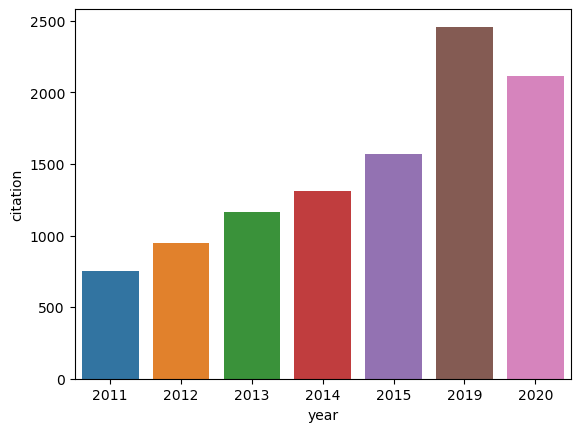

In [12]:
fig, ax = plt.subplots()
sns.barplot(data = count, x = "year", y = "citation", hue = "year",
           legend = False, ax = ax)
plt.show()

In [13]:
from sklearn.datasets import load_iris
iris = load_iris()
import pandas as pd
df = pd.DataFrame(data = iris.data, columns = iris.feature_names)
df['species']=iris.target

In [14]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


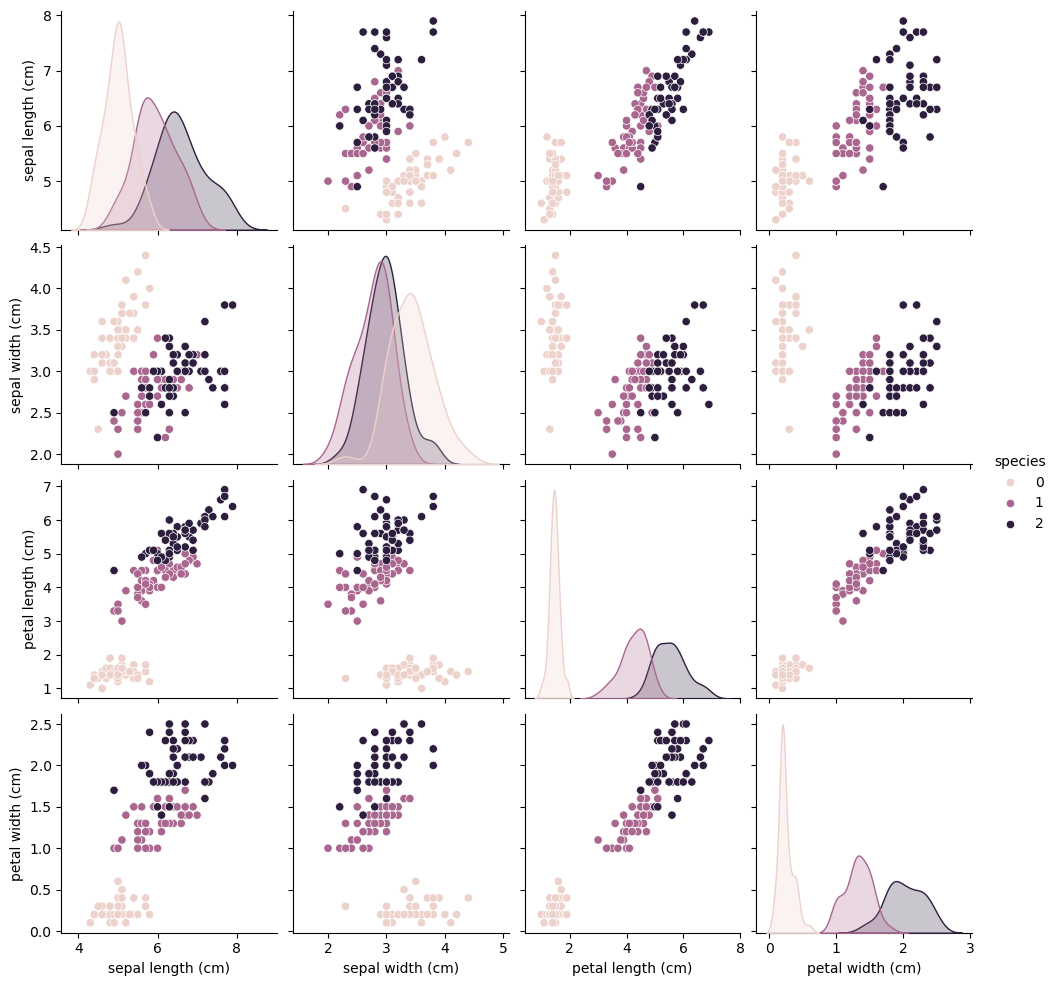

In [15]:
sns.pairplot( data= df, hue= 'species')

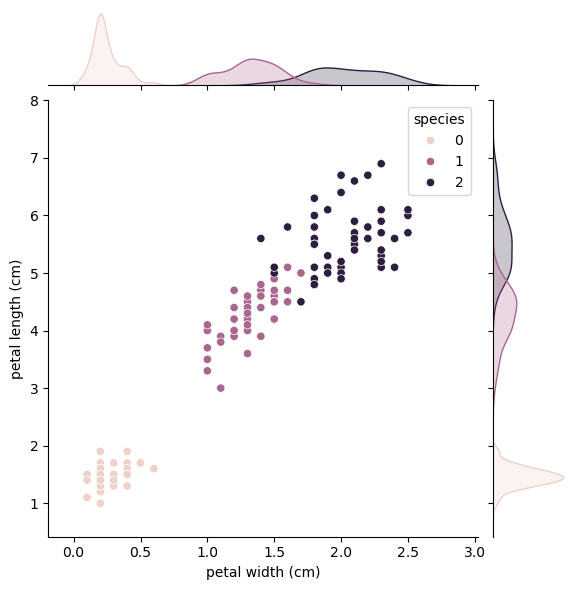

In [16]:
sns.jointplot(x='petal width (cm)', y='petal length (cm)', data = df, kind='scatter', hue='species')

## 원-핫 인코딩하기

In [17]:
penguins_encoding = pd.get_dummies(penguins, columns=['island', 'sex'])  #명목형 변수를 원핫인코딩

In [18]:
penguins_encoding.head()

,species,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_FEMALE,sex_MALE
0,Adelie,39.1,18.7,181.0,3750.0,False,False,True,False,True
1,Adelie,39.5,17.4,186.0,3800.0,False,False,True,True,False
2,Adelie,40.3,18.0,195.0,3250.0,False,False,True,True,False
4,Adelie,36.7,19.3,193.0,3450.0,False,False,True,True,False
5,Adelie,39.3,20.6,190.0,3650.0,False,False,True,False,True


## 훈련 데이터와 테스트 데이터로 분리하기

In [19]:
X = penguins_encoding.drop(['species'], axis = 1)  #독립변수
y = penguins_encoding['species']

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 11)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(233, 9) (100, 9) (233,) (100,)


## kNN 모델 생성, 학습하기

In [39]:
from sklearn.neighbors import KNeighborsClassifier
k = 11
knn = KNeighborsClassifier(n_neighbors=k) #모델 생성
knn.fit(X_train, y_train) #모델 학습

KNeighborsClassifier(n_neighbors=11)

In [49]:
print('knn accuracy:{:.3f}'.format(knn.score(X_test, y_test)))

knn accuracy:0.910


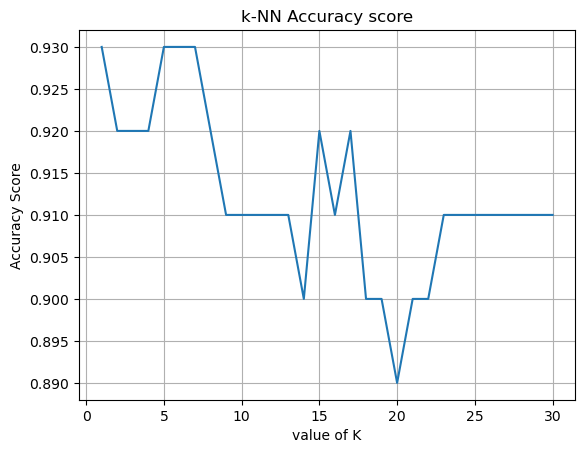

In [50]:
import numpy as np
import matplotlib.pyplot as plt
k_range = range(1, 31)
scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(X_train, y_train)
    scores.append(knn.score(X_test, y_test))

plt.plot(k_range, scores)
plt.xlabel('value of K')
plt.ylabel('Accuracy Score')
plt.xticks(np.arange(0, 31, 5))
plt.grid()
plt.title('k-NN Accuracy score')
plt.show()

In [51]:
y_pred = knn.predict(X_test)
y_pred[:20]

array(['Chinstrap', 'Gentoo', 'Adelie', 'Chinstrap', 'Gentoo', 'Adelie',
       'Gentoo', 'Gentoo', 'Chinstrap', 'Adelie', 'Adelie', 'Gentoo',
       'Chinstrap', 'Gentoo', 'Chinstrap', 'Chinstrap', 'Adelie',
       'Gentoo', 'Chinstrap', 'Adelie'], dtype=object)

In [52]:
for value, score in enumerate(scores):
    print('k={}일 때: accuracy:{:.3f}'.format(value + 1, score))

k=1일 때: accuracy:0.930
k=2일 때: accuracy:0.920
k=3일 때: accuracy:0.920
k=4일 때: accuracy:0.920
k=5일 때: accuracy:0.930
k=6일 때: accuracy:0.930
k=7일 때: accuracy:0.930
k=8일 때: accuracy:0.920
k=9일 때: accuracy:0.910
k=10일 때: accuracy:0.910
k=11일 때: accuracy:0.910
k=12일 때: accuracy:0.910
k=13일 때: accuracy:0.910
k=14일 때: accuracy:0.900
k=15일 때: accuracy:0.920
k=16일 때: accuracy:0.910
k=17일 때: accuracy:0.920
k=18일 때: accuracy:0.900
k=19일 때: accuracy:0.900
k=20일 때: accuracy:0.890
k=21일 때: accuracy:0.900
k=22일 때: accuracy:0.900
k=23일 때: accuracy:0.910
k=24일 때: accuracy:0.910
k=25일 때: accuracy:0.910
k=26일 때: accuracy:0.910
k=27일 때: accuracy:0.910
k=28일 때: accuracy:0.910
k=29일 때: accuracy:0.910
k=30일 때: accuracy:0.910


In [53]:
result = pd.DataFrame({
    '실제값' : y_test,
    '예측값' : y_pred})
result.head(20)

,실제값,예측값
156,Chinstrap,Chinstrap
272,Gentoo,Gentoo
108,Adelie,Adelie
165,Chinstrap,Chinstrap
240,Gentoo,Gentoo
107,Adelie,Adelie
227,Gentoo,Gentoo
235,Gentoo,Gentoo
176,Chinstrap,Chinstrap
19,Adelie,Adelie


## 펭귄 데이터셋의 2개의 속성만 이용하여 분류하기

In [54]:
X2 = penguins_encoding[['culmen_length_mm', 'flipper_length_mm']]   #해 보기: 2개의 속성만 이용

X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size = 0.3, random_state = 11)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(233, 2) (100, 2) (233,) (100,)


In [55]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=30)

In [56]:
print('knn accuracy:{:.3f}'.format(knn.score(X_test, y_test)))

knn accuracy:0.910


In [57]:
y_pred = knn.predict(X_test)
y_pred[:20]

result = pd.DataFrame({
    '실제값' : y_test,
    '예측값' : y_pred})
result.head(20)

,실제값,예측값
156,Chinstrap,Chinstrap
272,Gentoo,Gentoo
108,Adelie,Adelie
165,Chinstrap,Chinstrap
240,Gentoo,Gentoo
107,Adelie,Adelie
227,Gentoo,Gentoo
235,Gentoo,Gentoo
176,Chinstrap,Chinstrap
19,Adelie,Adelie


## 퀴즈
길을 가다 펭균을 한 마리 만났습니다.

'island': 'Biscoe',
</br>'culmen_length_mm': 42.0,
</br>'culmen_depth_mm': 18.0,
</br>'flipper_length_mm': 200,
</br>'body_mass_g': 4200,
</br>'sex': 'MALE'

이 펭귄은 무슨 펭귄일까요?

In [63]:
new_penguin = pd.DataFrame([{
    'island': 'Biscoe',
    'culmen_length_mm': 42.0,
    'culmen_depth_mm': 18.0,
    'flipper_length_mm': 200,
    'body_mass_g': 4200,
    'sex': 'MALE'
}])

In [74]:
print(knn.predict(new_penguin[X2.columns])[0])

Adelie
